---
---

<h1><center><ins>Exercise Sheet 6</ins></center></h1>
<h2><center>Numerical Methods <br>

---
---

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from numpy import log
from scipy.integrate import solve_ivp

""" 
Set some defaults, most of all: LARGE fonts
"""
import matplotlib.pylab as pylab
params = {'legend.fontsize': 'xx-large',
          'figure.figsize': (12, 7),
         'axes.labelsize': 'xx-large',
         'axes.titlesize':'xx-large',
         'xtick.labelsize':'xx-large',
         'ytick.labelsize':'xx-large'}
pylab.rcParams.update(params)

## Exercise 1 - Radioactive decay

Radioactive decay is the process by which an unstable atomic nucleus loses energy by radiation. The fundamental law of radioactive decay is based on the fact that the decay, i.e. the transition of a parent nucleus to a daughter nucleus is a purely statistical process. The disintegration (decay) probability is a fundamental property of an atomic nucleus and remains equal in time. Mathematically this law is expressed as: 

$$ \frac{d N}{dt} = - \lambda N \ , $$

where $N$ is the number of radioactive nuclei, $dN/dt$ the variation of this number per unit of time, and $\lambda$ is thus the probability of decay per nucleus per unit of time. A more intuitive representation of exponential decay is the time required for the decaying quantity to fall to one half of its initial value. This time, $t_{1/2}$, is called "half-life", and can be written in terms of the decay constant as:

$$ t_{1/2} = \frac{\ln(2)}{\lambda} \ . $$

Let's consider here Carbon-14, for which the decay constant is $\lambda \sim 1.21 \times 10^{-4}$ yr$^{-1}$, and which has a half-life $t_{1/2} \sim 5728$ yr. Its presence in organic materials is the basis of the radiocarbon dating method to date archaeological, geological and hydrogeological samples.

**(A)** Implement _**your own version**_ of the **Euler and Runge Kutta (order 2) algorithms**, and solve the differential equation above by using these methods. Compare the results you obtain to the analytic solution, which can be calculated as:

$$ N = N_0 \exp(-\lambda t) \ ,$$

where $N_0$ is the initial amount of the nuclei $[$i.e., $N(t = 0) = N_0]$.

**(B)** Compute your solution for a sufficient number of steps so that you can determine the **half-life** of Carbon-14. Pay attention to the size of the time-step you are using, and discuss your results when using different time-steps. Which method recovers a value of the half-life that is closer to the real one?

I don't see it in the lecture slides, but according to Wikipedia the Runge-Kutta method of order 2 is like this:
$$ y_{n+1} = y_n + h f ( t_n + \frac{1}{2} h, y_n + \frac{1}{2} h f(t_n , y_n)) $$

In [2]:
def euler(df, t0, tend, y0, dt):
    """
    df:     callable function, the derivative, can be a vector
    t0:     start time
    tend:   end time
    y0:     initial condition, can be a vector, must have same dimens as df
    dt:     time increment
    Forward Euler integration of a single or coupled system of ODE's
    RETURNS:
    ts:     an array of time instances, where the ODE was calculated
    ys:     an array of objects, which can be scalar or arrays, depending on the dimens of df and y0
            containing the results
    """
    ts = [t0]
    ys = [np.array(y0, dtype=float)]
    t = t0
    y = np.array(y0, dtype=float)

    while t < tend:
        h = min(dt, tend - t)       # if the last interval does not contain a full dt
        y = y + h * df(t, y)        # new y equals old y + dt * slope at old t
        t += h
        ys.append(y.copy())         # avoid side effects, remember that y can be a vector
        ts.append(t)
    return np.array(ts), np.array(ys)

def euler_cromer(df, dg, t0, tend, v0, x0, dt):
    """
    df:     callable function, the derivative of x
    dg:     callable function, the derivative of v
    t0:     start time
    tend:   end time
    v0:     initial speed
    x0:     initial position
    dt:     time increment
    Euler-Cromer integration of a system x-v of ODE's
    RETURNS:
    ts:     an array of time instances, where the ODE was calculated
    xs:     an array of x positions
    vs:     an array of velocities
    """
    ts = [t0]
    xs = [x0]
    vs = [v0]
    t = t0
    v, x = v0, x0
    while t < tend:
        h = min(dt, tend - t)
        v += h * dg(t, x)
        x += h * df(t, v)
        xs.append(x)
        vs.append(v)
        t = t + h
        ts.append(t)
    return np.array(ts), np.array(xs), np.array(vs)

def RK2(df, t0, tend, y0, dt):
    """
    df:     callable function, the derivative, can be a vector
    t0:     start time
    tend:   end time
    y0:     initial condition, can be a vector, must have same dimens as df
    dt:     time increment
    Runge-Kutta 2nd order (midpoint) integration of a single or coupled system of ODE's
    RETURNS:
    ts:     an array of time instances, where the ODE was calculated
    ys:     an array of objects, which can be scalar or arrays, depending on the dimens of df and y0
            containing the results
    """    
    ts = [t0]
    ys = [np.array(y0, dtype=float)]
    t = t0
    y = np.array(y0, dtype=float) 
    while t < tend:
        h = min(dt, tend - t)
        k1 = df(t, y)
        k2 = df(t + h/2, y + h/2 * k1)
        y = y + h * k2
        t += h
        ys.append(y.copy())
        ts.append(t)
    return np.array(ts), np.array(ys)  

def RK4(df, t0, tend, y0, dt):
    """
    df:     callable function, the derivative, can be a vector
    t0:     start time
    tend:   end time
    y0:     initial condition, can be a vector, must have same dimens as df
    dt:     time increment
    Runge-Kutte 4th order (classical) integration of a single or coupled system of ODE's
    RETURNS:
    ts:     an array of time instances, where the ODE was calculated
    ys:     an array of objects, which can be scalar or arrays, depending on the dimens of df and y0
            containing the results
    """    
    ts = [t0]
    ys = [np.array(y0, dtype=float)]
    t = t0
    y = np.array(y0, dtype=float) 
    while t < tend:
        h = min(dt, tend - t)
        k1 = df(t, y)
        k2 = df(t + h/2, y + h/2 * k1)
        k3 = df(t + h/2, y + h/2 * k2)
        k4 = df(t + h, y + h * k3)
        y = y + h / 6 * (k1 + 2*k2 + 2*k3 + k4)
        t += h
        ys.append(y.copy())
        ts.append(t)
    return np.array(ts), np.array(ys)  

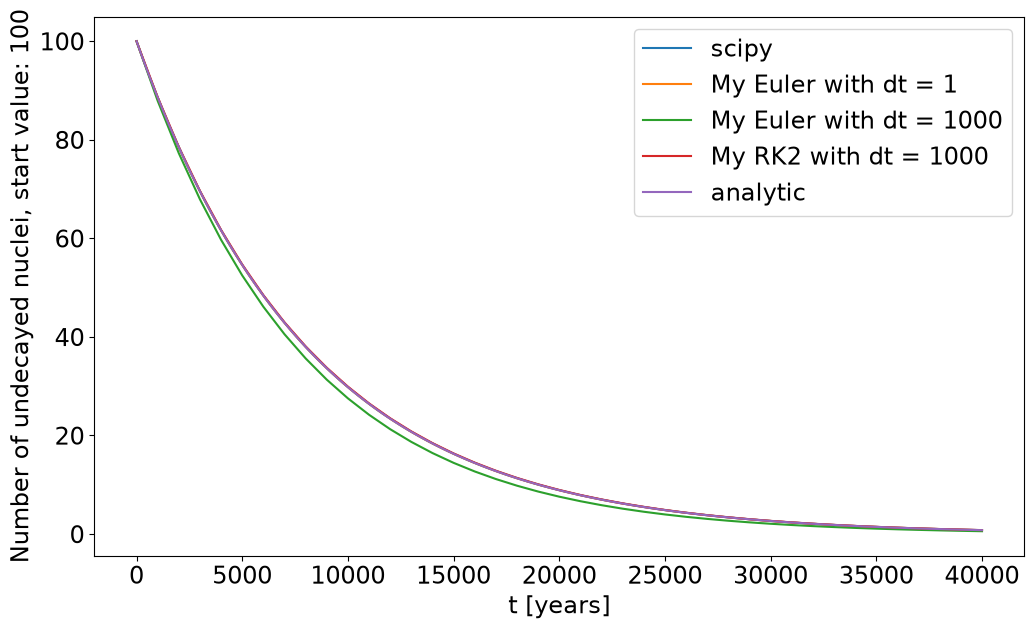

In [3]:
lamb = 1.21 * 10**(-4)
halflife = log(2)/lamb

N0 = 100
start_time = 0
end_time = 40_000
# first do it with scipy, as introduction

def decay(t, y):
    return - lamb * y

sol = solve_ivp(decay, [start_time, end_time], [N0], t_eval=np.linspace(start_time, end_time, 1000))
#print(sol)

def decay_analytic(t, lam, y0):
    return y0 * np.exp(-lam * t)

dt = 1
t, y = euler(decay, start_time, end_time, N0, dt)
t1000, y1000 = euler(decay, start_time, end_time, N0, 1000)
tk1000, yk1000 = RK2(decay, start_time, end_time, N0, 1000)

plt.figure()
plt.plot(sol.t, sol.y[0], label='scipy')
plt.plot(t, y, label=f'My Euler with dt = {dt}')
plt.plot(t1000, y1000, label=f'My Euler with dt = 1000')
plt.plot(tk1000, yk1000, label=f'My RK2 with dt = 1000')
plt.plot(t, decay_analytic(t, lamb, N0), label='analytic')
plt.xlabel('t [years]')
plt.ylabel(f'Number of undecayed nuclei, start value: {N0}')
plt.legend()
plt.show()


In [4]:
print(f'Analytical value: {halflife:.1f}')
for dt in [3000, 1000, 300, 100, 30, 10, 3, 1]:

    t, y = euler(decay, start_time, end_time, N0, dt)

    # we search in the y array for the index of the value, which minimizes the
    # difference to 1/2*N0, and with that index we look up in the t array 
    my_halflive = t[np.argmin(np.abs(y - 0.5 * N0))]
    print(f'For dT = {dt} the Euler halflive = {my_halflive} years, relative error {(abs(halflife - my_halflive) / halflife):.2%}')
    my_halflive = np.interp(0.5 * N0, y[::-1], t[::-1])
    print(f'For dT = {dt} the interpolated Euler halflive = {my_halflive:.1f} years, relative error {(abs(halflife - my_halflive) / halflife):.2%}')

    t, y = RK2(decay, start_time, end_time, N0, dt)
    my_halflive = t[np.argmin(np.abs(y - 0.5 * N0))]
    print(f'For dT = {dt} the RK2 halflive = {my_halflive} years, relative error {(abs(halflife - my_halflive) / halflife):.2%}')
    my_halflive = np.interp(0.5 * N0, y[::-1], t[::-1])
    print(f'For dT = {dt} the interpolated RK2 halflive = {my_halflive:.1f} years, relative error {(abs(halflife - my_halflive) / halflife):.2%}')
    print()

Analytical value: 5728.5
For dT = 3000 the Euler halflive = 6000 years, relative error 4.74%
For dT = 3000 the interpolated Euler halflive = 4777.4 years, relative error 16.60%
For dT = 3000 the RK2 halflive = 6000 years, relative error 4.74%
For dT = 3000 the interpolated RK2 halflive = 5914.5 years, relative error 3.25%

For dT = 1000 the Euler halflive = 5000 years, relative error 12.72%
For dT = 1000 the interpolated Euler halflive = 5389.6 years, relative error 5.91%
For dT = 1000 the RK2 halflive = 6000 years, relative error 4.74%
For dT = 1000 the interpolated RK2 halflive = 5755.2 years, relative error 0.47%

For dT = 300 the Euler halflive = 5700 years, relative error 0.50%
For dT = 300 the interpolated Euler halflive = 5624.9 years, relative error 1.81%
For dT = 300 the RK2 halflive = 5700 years, relative error 0.50%
For dT = 300 the interpolated RK2 halflive = 5730.3 years, relative error 0.03%

For dT = 100 the Euler halflive = 5700 years, relative error 0.50%
For dT = 100 

In [5]:
# We will now use the solve_ip with the event detection in order to detect the halflive time
# events are detected when the passed function changes sign
# y[0] is the actual 'position', in this case the remaining amount
# and when that passes half the initial amount, we reached the half life time
# the t_events is a 2D array, with one dimension for the ODE's (in our case only scalar)
# and one dimension for all events encountered. Our function is monotonous, so we 
# get only one event

def half(t, y):
    return y[0] - N0/2

sol = solve_ivp(decay, [start_time, end_time], [N0], 
                rtol=1e-6, atol=1e-9, t_eval=np.linspace(start_time, end_time, 1000), events=half)
print(sol)
my_halflive = sol.t_events[0][0]
print(f'The SciPy halflive = {my_halflive:.1f} years, relative error {(abs(halflife - my_halflive) / halflife):.2%}')

  message: The solver successfully reached the end of the integration interval.
  success: True
   status: 0
        t: [ 0.000e+00  4.004e+01 ...  3.996e+04  4.000e+04]
        y: [[ 1.000e+02  9.952e+01 ...  7.945e-01  7.907e-01]]
      sol: None
 t_events: [array([ 5.728e+03])]
 y_events: [array([[ 5.000e+01]])]
     nfev: 158
     njev: 0
      nlu: 0
The SciPy halflive = 5728.5 years, relative error 0.00%


In the comparison of the analytical, the SciPy (RK45), my RK2 and my Euler, any dt < 200 gives no visible difference in the curve in the interval [0, 40_000]. The curves basically overlap in this regime. I plotted above one Euler result with dt = 1000, which is the only visibly off curve, being consistently below the correct curve. For this function, it is logical that Euler is always below the true curve: the $2^{nd}$ of $e^{-x}$ is always positive, and since in forward Euler it is evaluated at the beginning of each interval, we consistently get a too low value.
In comparison between Euler and Runge-Kutta of order 2: in the curves, a dt of 1000 and lower gives good results (error < 1%) with RK2, but with Euler a dt <= 100 is needed for this accuracy . For calculating the halftime, when not interpolating between timesteps, we can see at the best the resolution of the timestep, but with interpolating we can appreciate the superiority of RK2: its relative error is lower by about an order of magnitude compared with forward Euler.

## Exercise 2 - The motion of a pendulum

The differential equation describing the motion of a simple pendulum of length $l$ is

$$ \frac{d^2 \theta}{dt} = - \frac{g}{l} \sin(\theta) \ , $$

where $g$ is the local acceleration of gravity (on Earth, $g = 9.8$ m/s$^2$). For this exercise, consider $l = 10$ m. Here we will consider the simple case in which the maximal displacement of the pendulum is small, so that we can use the approximation $\sin(\theta) \approx \theta$ and consider the following, simplified, equation:

$$ \frac{d^2 \theta}{dt} = - \frac{g}{l} \theta \ . $$

This equation can be solved analytically, giving the following expression for $\theta(t)$:

$$ \theta(t) = \theta_0 \cos \left(\sqrt{\frac{g}{l}} \, t \right) \ .$$

**(A)** Rewrite the above differential equation as a system of first-order differential equations, and solve it numerically by implementing _**your own version**_ of the **Euler method**. Consider that at a time $t = 0$ the pendulum is at $\theta = 0.1$ radians, and it is not moving. 

**(B)** What is the displacement ($\theta$) of the pendulum at a time $t = 20$ s, if you consider a time step $\tau = 0.2$ s in your ODE integrator? How different is the value you obtain from the true one (calculated with the above equation)? How small should the time step be, if you want to have a discrepancy of at most 0.01 in the value of $\theta(t = 20$ s$)$?

**(C)** Implement _**your own version**_ of the **Euler-Cromer and Runge Kutta (order 4) algorithms**, and solve the differential equation again by using these methods. How big is the discrepancy from the real solution for these methods, at a time $t = 20$ s, if you consider a time step $\tau = 0.2$ s?

$$\theta_1 = \frac{d\theta}{dt}, \theta_2 = \theta$$
$$\frac{d\theta_1}{dt} = \frac{d^2 \theta}{dt^2} = - \frac{g}{l} \theta $$
$$ \frac{d\theta_2}{dt} = \theta_1 $$
In vector form this becomes:
$$ \frac{d}{dt}
\begin{pmatrix}
\theta_1\\
\theta_2
\end{pmatrix}
=
\begin{pmatrix}
-\frac{g}{l}\theta_2\\
\theta_1
\end{pmatrix} $$

dt = 0.2: ForwardEuler displacement at 20.0 s: 0.5245069552491984, analytical: 0.05821434287267862, difference: 0.4662926123765198
dt = 0.2: Euler-Cromer displacement at 20.0 s: 0.04727036058673173, analytical: 0.05821434287267862, difference: 0.010943982285946889
dt = 0.2: Runge-Kutta4 displacement at 20.0 s: 0.05823224356749842, analytical: 0.05821434287267862, difference: 1.7900694819800167e-05

dt = 0.1: ForwardEuler displacement at 20.0 s: 0.16790642477691936, analytical: 0.05821434287267862, difference: 0.10969208190424073
dt = 0.1: Euler-Cromer displacement at 20.0 s: 0.053501643373562044, analytical: 0.05821434287267862, difference: 0.004712699499116575
dt = 0.1: Runge-Kutta4 displacement at 20.0 s: 0.05821555075136206, analytical: 0.05821434287267862, difference: 1.2078786834415767e-06

dt = 0.05: ForwardEuler displacement at 20.0 s: 0.0970963794004453, analytical: 0.05821434287267862, difference: 0.03888203652776668
dt = 0.05: Euler-Cromer displacement at 20.0 s: 0.0560340305

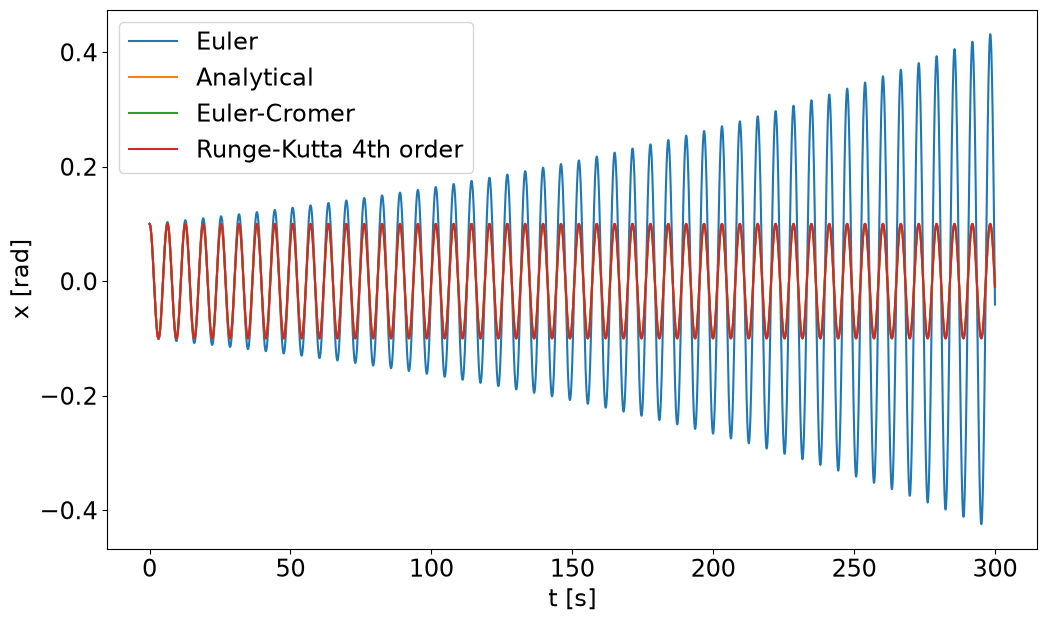

In [6]:
g, l = 9.8,10
x_0, v_0 = 0.1, 0
def pendulum(t, y):
    x1, x2 = y

    dx1 = - (g / l) * x2
    dx2 = x1

    return np.array([dx1, dx2])

def df(t, v):
    return v

def dg(t, x):
    return -g / l * x

y0 = np.array([v_0, x_0])

dts = [0.2, 0.1, 0.05, 0.02, 0.01]

for dt in dts:
    analytical = x_0 * np.cos(np.sqrt(g/l) * 20)

    t, y = euler(pendulum, 0, 20, y0, dt)
    print(f'dt = {dt}: ForwardEuler displacement at {t[-1]} s: {y[-1][1]}, analytical: {analytical}, difference: {abs(y[-1][1] - analytical)}')

    t_ec, x_ec, v_ec = euler_cromer(df, dg, 0, 20, v_0, x_0, dt)
    print(f'dt = {dt}: Euler-Cromer displacement at {t_ec[-1]} s: {x_ec[-1]}, analytical: {analytical}, difference: {abs(x_ec[-1] - analytical)}')
    
    t_rk4, x_rk4 = RK4(pendulum, 0, 20, y0, dt)
    print(f'dt = {dt}: Runge-Kutta4 displacement at {t_rk4[-1]} s: {x_rk4[-1, 1]}, analytical: {analytical}, difference: {abs(x_rk4[-1, 1] - analytical)}\n')

tend = 300
t, y = euler(pendulum, 0, tend, y0, 0.01)
t_ec, x_ec, v_ec = euler_cromer(df, dg, 0, tend, v_0, x_0, 0.01)
t_rk4, x_rk4 = RK4(pendulum, 0, tend, y0, 0.01)

plt.plot(t, y[:, 1], label="Euler")
plt.plot(t, x_0 * np.cos(np.sqrt(g/l) * t),
         label="Analytical")
plt.plot(t_ec, x_ec, label='Euler-Cromer')
plt.plot(t_rk4, x_rk4[:, 1], label='Runge-Kutta 4th order')
plt.xlabel("t [s]")
plt.ylabel("x [rad]")
plt.legend()
plt.show()

## Exercise 3 - Motion of a mass attached to a spring

The differential equation describing the motion of a particle attached to a spring can be obtained by putting together Newton's 2nd law and Hooke's law, and it can be written as:

$$ \frac{d^2 x}{dt^2} = - \frac{k}{m} x \ , $$

where $m$ is the mass of your particle, $k$ is the spring constant, and $x$ is the displacement from the equilibrium position.

**(A)** Choose some reasonable values for $k$ and $m$, define the initial conditions of your problem, and compute the analytic solution of your specific system, considering that the general solution is given by:

$$ x(t) = x_0 \cos\left(\sqrt{\frac{k}{m}} \, t\right) + v_0 \sqrt{\frac{m}{k}} \sin \left(\sqrt{\frac{k}{m}} \, t\right) \ , $$

where $x_0$ and $v_0$ are the position and velocity of the particle at time $t = 0$.

**(B)** Rewrite the above differential equation as a system of first-order differential equations, and solve it numerically _**by using one of the built-in python methods**_ (take a look at the available methods in the `scipy` package).

**(C)** Plot your solution and compare it to the analytical solution.

For simplicity I chose a simple initial condition, for fun, I chose the antisymmetric to the pendulum, i.e. $x_0 = 0$ and $v_0 = 0.1$. It is obvious, that in that case I keep only the sin term of the general solution. The $\omega^2 = \frac{k}{m}$ adds no information for this example, so I will assume $\omega^2 = 1$. The separation of variables is totally the same as for the pendulum above:
$$x_1 = \frac{dx}{dt}, x_2 = x$$
$$\frac{dx_1}{dt} = \frac{d^2 x}{dt^2} = - x $$
$$ \frac{dx_2}{dt} = x_1 $$
In vector form this becomes:
$$ \frac{d}{dt}
\begin{pmatrix}
x_1\\
x_2
\end{pmatrix}
=
\begin{pmatrix}
-x_2\\
x_1
\end{pmatrix} $$

  message: The solver successfully reached the end of the integration interval.
  success: True
   status: 0
        t: [ 0.000e+00  1.001e-01 ...  9.990e+01  1.000e+02]
        y: [[ 1.000e-01  9.950e-02 ...  8.074e-02  8.623e-02]
            [ 0.000e+00  9.993e-03 ... -5.900e-02 -5.064e-02]]
      sol: None
 t_events: None
 y_events: None
     nfev: 12266
     njev: 0
      nlu: 0


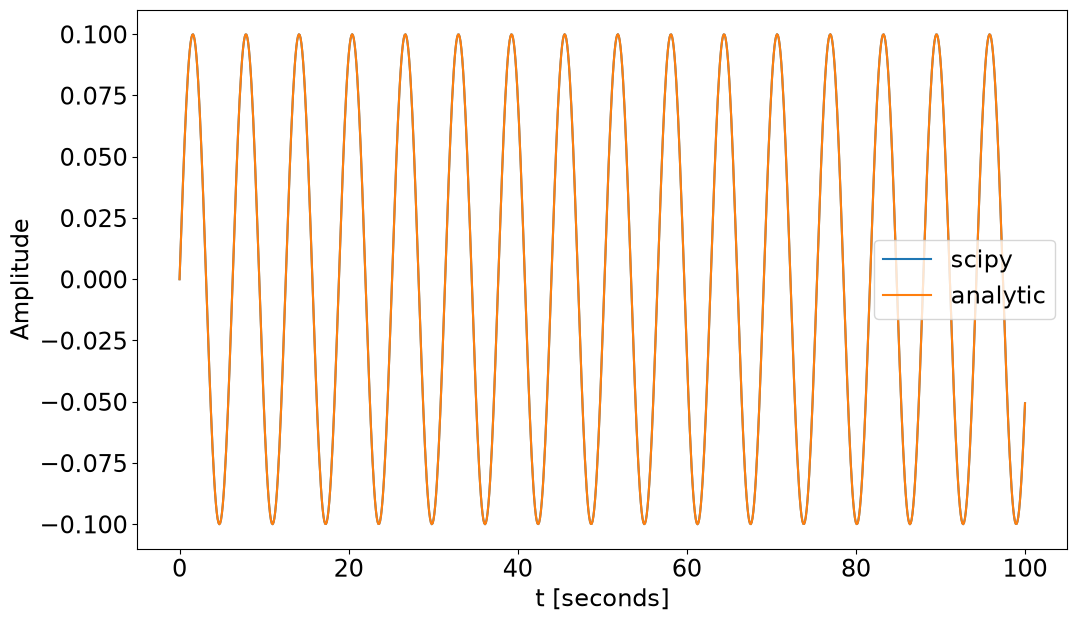

In [7]:
k, m = 1, 1
x_0, v_0 = 0, 0.1
start_time = 0
end_time = 100

def spring(t, y):
    x1, x2 = y

    dx1 = - x2
    dx2 = x1

    return np.array([dx1, dx2])

y0 = np.array([v_0, x_0])

def spring_analytic(t):
    return v_0 * np.sin(np.sqrt(k/m) * t)

sol = solve_ivp(spring, [start_time, end_time], y0, t_eval=np.linspace(start_time, end_time, 1000), rtol=1e-9, atol=1e-12)
print(sol)

plt.figure()
plt.plot(sol.t, sol.y[1], label='scipy')
plt.plot(sol.t, spring_analytic(sol.t), label='analytic')
plt.xlabel('t [seconds]')
plt.ylabel(f'Amplitude')
plt.legend()
plt.show()



RK23     error = 8.329e-09, evaluations = 125840
RK45     error = 1.224e-09, evaluations = 12266
DOP853   error = 7.306e-10, evaluations = 2834
Radau    error = 3.552e-12, evaluations = 36551
LSODA    error = 4.807e-09, evaluations = 2832
BDF      error = 7.423e-08, evaluations = 6349


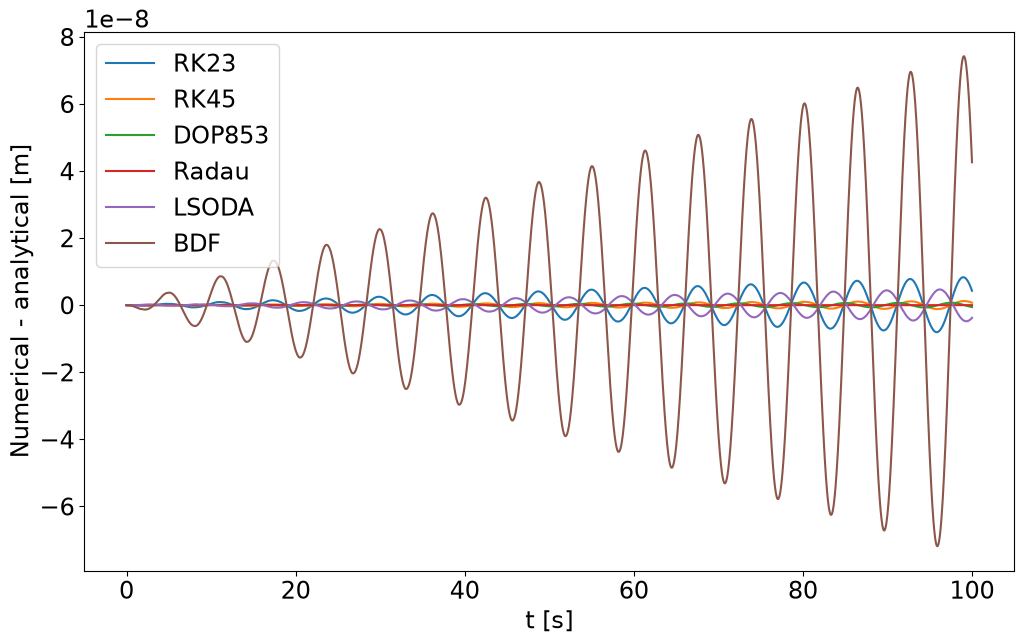

In [8]:
methods = ["RK23", "RK45", "DOP853",
           "Radau", "LSODA", "BDF"]


plt.figure()
for method in methods:
    sol = solve_ivp(
        spring,
        [0, 100],
        y0,
        method=method,
        rtol=1e-9,
        atol=1e-12
    )

    exact = spring_analytic(sol.t)
    error = np.max(np.abs(sol.y[1] - exact))

    print(f"{method:8s} error = {error:.3e}, "
          f"evaluations = {sol.nfev}")
    
    error = sol.y[1] - spring_analytic(sol.t)

    plt.plot(sol.t, error, label=method)

plt.xlabel("t [s]")
plt.ylabel("Numerical - analytical [m]")
plt.legend()
plt.show()

![Bildschirmfoto 2026-11-20 um 17.31.33.png](<attachment:Bildschirmfoto 2026-11-20 um 17.31.33.png>)
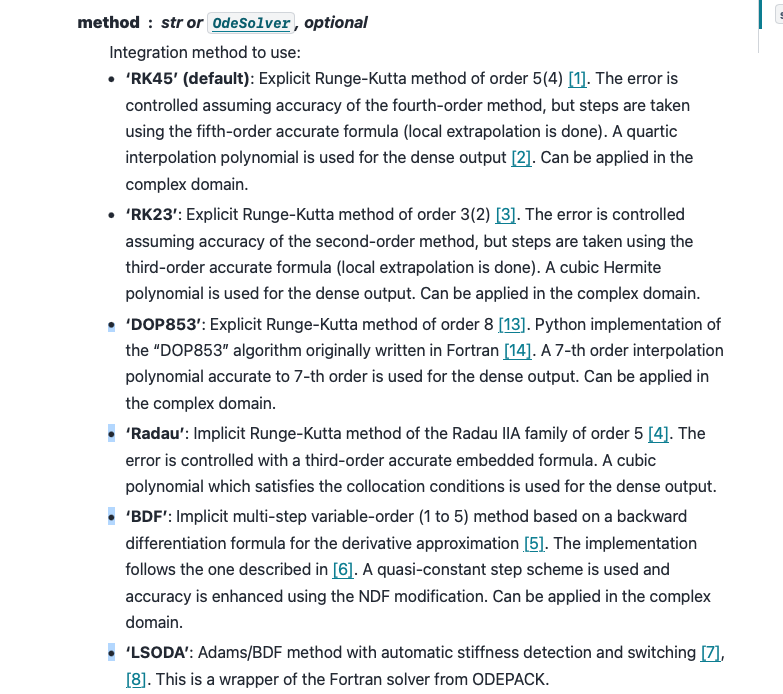